# ⚙️ SECOM 반도체 공정 데이터 분석 - Day 3 종합 마스터 노트북
## 공정 시계열 분석(R05), 챔버 열화 PdM(전략 1-1), SHAP XAI 원인 규명(전략 2), 신규 웨이퍼 실시간 배치 시뮬레이터(전략 4), 종합 리포트 엔진(`make_report`) 및 C01~C08 전수 검증

---
- **실행 환경**: miniconda `DS` 환경 (`Python (DS)`)
- **기준 가이드 문서**: `docs/Day3_작업_가이드.md` 및 `docs/Day3_고도화_전략_가이드.html`
- **핵심 목표**:
  1. 공정 시간 정보(Timestamp)를 활용한 일별/주별 생산량 및 불량 변곡점(Trouble Period) 탐색 (R05 고도화)
  2. **[전략 1-1]** 챔버 내벽 파티클 누적(CVD 상승) 및 전극 마모(Dry Etch 하강)를 대변하는 3대 다면 통계 모델 기반 센서 드리프트(Sensor Drift) 탐지 엔진 구현
  3. **[전략 2]** SHAP TreeExplainer 기반 실무 투트랙(Two-Track) XAI: 진짜 불량 적발 1호(`sample_id = 1254`) 결함 규명 + 가양성 오탐 1위(`sample_id = 242`) 오탐 메커니즘 해명 및 글로벌 Top 15 센서 중요도 도출
  4. **[전략 4]** 신규 웨이퍼 CSV 실시간 배치 인퍼런스 시뮬레이터 (단 0.1초 만에 232개 센서 전처리 + 추론 + Top 20% 우선 검토 큐 배정)
  5. 기획서 Section 09, 10 필수 산출물인 종합 진단 보고서 자동 생성 엔진 (`make_report`) 및 UTF-8-SIG 한글 엑셀 무결성 검증
  6. 기획서 C07, C08 및 고도화 D03-ADV 1~3 전 항목 100% PASS 달성

## 1. 실행 환경 점검 및 Day 1 / Day 2 영속화 산출물 무결성 로드

### 💡 도메인 및 엔지니어링 배경 (데이터 누수 방지 원칙)
- Day 1에서 우리는 **8:2 층화 분리(Train 1,253건 : Test 314건)**를 수행하여 데이터 누수를 완벽 차단했습니다.
- Day 2에서는 4단계 고도화 실험(Ablation Study)을 통해 **불량 15건(Recall 71.4%)을 적발하는 챔피언 모델**(`EnhancedLGBMClassifier`)을 확립했습니다.
- Day 3에서는 공정 시간 정보(타임스탬프)를 활용하되, **Train/Test 분리 기준선을 절대 침범하지 않고** 사후 트렌드 분석, 설비 예지보전(PdM), 인공지능 설명(XAI) 및 신규 웨이퍼 배치 추론으로 안전하게 연결합니다.

In [1]:
import os
import sys
import math
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import shap

# 한글 폰트 및 시각화 기본 설정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
mpl.rcParams['figure.dpi'] = 120

# 프로젝트 루트 경로 보정 (notebooks 하위에서 실행 시 상위로 이동)
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
base_dir = os.getcwd()
sys.path.append(base_dir)

from src.analysis import (
    summarize_data,
    calculate_review_metrics,
    compare_reference,
    analyze_timeseries_trend,
    detect_sensor_drift,
    make_report,
    explain_sample_shap,
    get_global_shap_importance,
    simulate_batch_inference,
    verify_c07_c08,
    verify_day3_advanced_integrity,
    EnhancedLGBMClassifier
)

# 1. 정제 데이터 및 라벨 로드
df_features = pd.read_csv("data/processed/secom_features.csv")
df_labels = pd.read_csv("data/processed/secom_labels.csv")
df_labels["timestamp"] = pd.to_datetime(df_labels["timestamp"])

# 2. 영속화 전처리 파이프라인 및 챔피언 모델 로드
prep_dict = joblib.load("artifacts/preprocessor.joblib")
valid_features = prep_dict["valid_features"]
model = joblib.load("artifacts/baseline_model.joblib")
df_train_idx = pd.read_csv("artifacts/train_indices.csv")
df_predictions = pd.read_csv("artifacts/test_predictions.csv")

train_normal_ids = df_train_idx[df_train_idx["label"] == 0]["sample_id"].values
test_ids = df_predictions["sample_id"].values

print("=" * 75)
print("🛡️ [1-1] Day 3 기반 데이터 및 영속화 객체 무결성 로드 완료")
print("=" * 75)
print(f"  - 전체 피처 형상       : {df_features.shape}")
print(f"  - 전체 라벨 형상       : {df_labels.shape}")
print(f"  - 모델링 유효 센서 수   : {len(valid_features)} 개 (다중공선성 해소 완료)")
print(f"  - 활성 챔피언 모델      : {type(model).__name__}")
print(f"  - 시험 예측표 표본 수   : {len(df_predictions)} 건 (상위 20% 불량 {df_predictions[df_predictions['is_top20pct']==True]['actual_label'].sum()}건 적발)")
print(f"  - SHAP 라이브러리 버전  : {shap.__version__}")
print("=" * 75)

🛡️ [1-1] Day 3 기반 데이터 및 영속화 객체 무결성 로드 완료
  - 전체 피처 형상       : (1567, 591)
  - 전체 라벨 형상       : (1567, 4)
  - 모델링 유효 센서 수   : 232 개 (다중공선성 해소 완료)
  - 활성 챔피언 모델      : EnhancedLGBMClassifier
  - 시험 예측표 표본 수   : 314 건 (상위 20% 불량 15건 적발)
  - SHAP 라이브러리 버전  : 0.49.1


## 2. 공정 시간 정보(Timestamp) 기반 시계열 심층 분석 (R05 고도화)

### 💡 왜 시계열 트렌드 분석이 필요한가?
- SECOM 데이터는 2008년 7월 19일부터 2008년 10월 10일까지 약 3개월간 기록되었습니다.
- 반도체 공정은 단일 웨이퍼 단위로 독립적인 것이 아니라, 동일한 설비 챔버에서 **연속 배치(Batch) 단위로 가공**됩니다.
- 따라서 일별/주별 불량률 추이를 파악하고 **7일 롤링 이동 불량률(Rolling 7-day Failure Rate)**을 산출하면, 공정 설비에 일시적인 쇼크나 이상이 발생했던 기간(Trouble Period)을 명확히 식별할 수 있습니다.

In [2]:
# 공정 시계열 추이 분석 함수 호출
ts_result = analyze_timeseries_trend(df_labels)

daily_df = ts_result["daily"]
weekly_df = ts_result["weekly"]
trouble_days = ts_result["trouble_days"]
min_date, max_date = ts_result["date_range"]

print("=" * 75)
print(f"📅 [2-1] SECOM 공정 가동 기간: {min_date} ~ {max_date} (총 {len(daily_df)} 가동일)")
print("=" * 75)
print("📊 [일별 생산 및 불량 통계 (최근 5일)]")
display(daily_df.tail(5))

print("\n📊 [주별 생산량 및 불량률 통계]")
display(weekly_df)

📅 [2-1] SECOM 공정 가동 기간: 2008-07-19 ~ 2008-10-17 (총 86 가동일)
📊 [일별 생산 및 불량 통계 (최근 5일)]


,date,total_wafers,fail_wafers,fail_rate,rolling_7d_fail_rate
81,2008-10-13,22,0,0.000000,4.081633
82,2008-10-14,16,0,0.000000,3.571429
83,2008-10-15,34,1,2.941176,3.991597
84,2008-10-16,19,0,0.000000,0.420168
85,2008-10-17,3,0,0.000000,0.420168



📊 [주별 생산량 및 불량률 통계]


,year_week,start_date,total_wafers,fail_wafers,fail_rate
0,2008-W28,2008-07-19 11:55:00,12,3,25.000000
1,2008-W29,2008-07-20 03:35:00,12,2,16.666667
2,2008-W30,2008-07-27 04:18:00,48,10,20.833333
3,2008-W31,2008-08-03 13:09:00,106,9,8.490566
4,2008-W32,2008-08-10 00:09:00,46,7,15.217391
5,2008-W33,2008-08-17 00:52:00,218,26,11.926606
6,2008-W34,2008-08-24 02:32:00,158,6,3.797468
7,2008-W35,2008-08-31 02:57:00,136,4,2.941176
8,2008-W36,2008-09-07 00:08:00,96,4,4.166667
9,2008-W37,2008-09-14 02:50:00,137,5,3.649635


## 3. 공정 이상 트러블 일자(Trouble Period) 집중 분석

### 💡 변곡점 발견: 왜 8월 중순에 불량이 급증했는가?
- 일별 통계를 정렬해보면, **2008년 8월 10일**의 경우 12개 생산 웨이퍼 중 무려 **5개(41.67%)가 불량**으로 판정되었습니다.
- 7일 롤링 이동 평균 불량률 역시 **8월 중순 15.8%까지 치솟는 극심한 공정 스파이크**를 나타냅니다.
- 이는 통상적인 일일 불량률(6.6%)의 6배를 초과하는 심각한 공정 쇼크이며, 특정 챔버의 가스 누출, 압력 제어 실패 또는 원자재 결함이 발생했던 시기임을 강하게 시사합니다.

In [3]:
print("=" * 75)
print("🚨 [3-1] 공정 불량률 상위 5대 트러블 일자 (생산량 5건 이상 기준)")
print("=" * 75)
display(trouble_days)

# 트러블 일자 웨이퍼들의 ID 추출
trouble_date = trouble_days.iloc[0]["date"]
df_labels_temp = df_labels.copy()
df_labels_temp["date"] = df_labels_temp["timestamp"].dt.date
trouble_sample_ids = df_labels_temp[df_labels_temp["date"] == trouble_date]["sample_id"].tolist()

print(f"\n🎯 최대 트러블 일자({trouble_date}) 생산 웨이퍼 수: {len(trouble_sample_ids)}개")
print(f"   - 샘플 ID 목록: {trouble_sample_ids[:10]}")

🚨 [3-1] 공정 불량률 상위 5대 트러블 일자 (생산량 5건 이상 기준)


,date,total_wafers,fail_wafers,fail_rate,rolling_7d_fail_rate
0,2008-08-10,12,5,41.666667,15.802900
1,2008-07-30,5,2,40.000000,28.333333
2,2008-07-29,12,4,33.333333,29.761905
3,2008-08-17,17,5,29.411765,12.535014
4,2008-07-19,12,3,25.000000,25.000000



🎯 최대 트러블 일자(2008-08-10) 생산 웨이퍼 수: 12개
   - 샘플 ID 목록: [178, 179, 180, 181, 182, 183, 184, 185, 186, 187]


## 4. [전략 1-1] 챔버 열화 및 센서 드리프트(Sensor Drift) 고도화 통계 판별 엔진

### 💡 단순 피어슨 상관계수(|r|)의 한계와 착시 현상
- 단순 피어슨 상관계수(|r|)만으로 드리프트를 탐지하면 심각한 착시와 오류가 발생합니다:
  1. **스케일 왜곡 (Scale Artifact)**: `feature_79`처럼 센서의 절대 표준편차(0.048)가 매우 작은 경우, 간헐적 스파이크 때문에 Y축 스케일이 넓어져 실제 변화량(-0.035 ➔ -0.015)이 시각적으로는 **수평선**처럼 보입니다.
  2. **결측치 대체 왜곡 (Imputation Artifact)**: 후반부에 결측치가 몰린 센서는 중앙값(Median)으로 일괄 대체되면서 후반부에 인위적인 '일자 수평선'이 형성됩니다.
  3. **경사도 및 효과 크기(Effect Size) 무시**: 데이터가 직선 주변에 얼마나 밀집했는지만 볼 뿐, **"실제로 장비 기준축이 몇 표준편차(σ)나 이동했는가"**를 측정하지 못합니다.

### 🔬 [고도화 해법] 3대 다면 평가 모델 (Tri-Criteria Drift Engine)
본 시스템은 단순 상관계수를 넘어 3단계 통계 모델로 **'확실한 상승'**과 **'확실한 하강'**을 엄밀히 분리합니다:
1. **켄달 타우 비모수 단조성 검정 (Kendall $\tau$)**: 스파이크 이상치에 왜곡되지 않는 순위 단조 경향성 검증.
2. **표준화 기울기 (Normalized Drift, $\Delta \sigma$)**: $\Delta \sigma = (\text{Slope} \times N) / \sigma$. 3개월 생산 기간 동안 센서 기준축이 **몇 표준편차($\sigma$)만큼 실제로 이동했는가**를 측정 ($|\Delta \sigma| \ge 1.0\sigma$).
3. **기저 이동 효과 크기 (Standardized Shift, $\Delta \mu / \sigma$)**: 초기 100개 vs 후기 100개 웨이퍼 간 실질적 평균 변화율 ($|\Delta \mu / \sigma| \ge 0.70\sigma$).
4. **종합 드리프트 판별 지수 (Drift Index)**: $|\Delta \sigma| \times \sqrt{|r \cdot \tau|}$ (변화량 크기와 경향성의 기하평균).

In [4]:
# 1. 확실한 상승 드리프트 상위 3대 센서 탐지 (CVD/증착/파티클 축적형)
drift_up = detect_sensor_drift(df_features, df_labels, valid_features, top_n=3, filter_mode="upward")

# 2. 확실한 하강 드리프트 상위 3대 센서 탐지 (Dry Etch/식각/전극 마모형)
drift_down = detect_sensor_drift(df_features, df_labels, valid_features, top_n=3, filter_mode="downward")

# 3. 종합 병합 테이블
top_drift = pd.concat([drift_up, drift_down], ignore_index=True)

print("=" * 95)
print("🔬 [4-1] 3대 다면 통계 모델 기반 확실한 상승/하강 드리프트 센서 판별 결과 (각 3대씩)")
print("=" * 95)
display(top_drift[["sensor_id", "drift_index", "direction", "norm_drift_sigma", "std_shift_sigma", "pearson_r", "kendall_tau", "start_mean", "end_mean", "shift_pct"]])

print("\n💡 [물리적 공정 해석]")
print("  🚀 [상승 드리프트 - 증착/파티클 누적형]")
for _, row in drift_up.iterrows():
    print(f"    • {row['sensor_id']}: 지수={row['drift_index']:.4f}, 누적이동={row['norm_drift_sigma']:+.2f}σ, "
          f"초기 {row['start_mean']:.4f} ➔ 후기 {row['end_mean']:.4f} ({row['shift_pct']:+.1f}%)")

print("\n  📉 [하강 드리프트 - 식각/소모품 마모형]")
for _, row in drift_down.iterrows():
    print(f"    • {row['sensor_id']}: 지수={row['drift_index']:.4f}, 누적이동={row['norm_drift_sigma']:+.2f}σ, "
          f"초기 {row['start_mean']:.4f} ➔ 후기 {row['end_mean']:.4f} ({row['shift_pct']:+.1f}%)")

🔬 [4-1] 3대 다면 통계 모델 기반 확실한 상승/하강 드리프트 센서 판별 결과 (각 3대씩)


,sensor_id,drift_index,direction,norm_drift_sigma,std_shift_sigma,pearson_r,kendall_tau,start_mean,end_mean,shift_pct
0,feature_29,1.0011,확실한 상승 (Upward),2.04,2.01,0.5905,0.4059,65.2962,72.2466,10.64
1,feature_543,0.7448,확실한 상승 (Upward),1.78,1.54,0.5142,0.3402,0.1097,0.1139,3.85
2,feature_170,0.5656,확실한 상승 (Upward),1.53,0.98,0.4424,0.3081,0.2830,0.4766,68.38
3,feature_104,0.7360,확실한 하강 (Downward),-1.73,-1.57,-0.4991,-0.3634,-0.0064,-0.0113,-74.73
4,feature_80,0.6762,확실한 하강 (Downward),-1.71,-1.30,-0.4939,-0.3165,0.0283,-0.0015,-105.33
5,feature_60,0.5490,확실한 하강 (Downward),-1.49,-1.31,-0.4304,-0.3151,12.6070,0.1150,-99.09



💡 [물리적 공정 해석]
  🚀 [상승 드리프트 - 증착/파티클 누적형]
    • feature_29: 지수=1.0011, 누적이동=+2.04σ, 초기 65.2962 ➔ 후기 72.2466 (+10.6%)
    • feature_543: 지수=0.7448, 누적이동=+1.78σ, 초기 0.1097 ➔ 후기 0.1139 (+3.9%)
    • feature_170: 지수=0.5656, 누적이동=+1.53σ, 초기 0.2830 ➔ 후기 0.4766 (+68.4%)

  📉 [하강 드리프트 - 식각/소모품 마모형]
    • feature_104: 지수=0.7360, 누적이동=-1.73σ, 초기 -0.0064 ➔ 후기 -0.0113 (-74.7%)
    • feature_80: 지수=0.6762, 누적이동=-1.71σ, 초기 0.0283 ➔ 후기 -0.0015 (-105.3%)
    • feature_60: 지수=0.5490, 누적이동=-1.49σ, 초기 12.6070 ➔ 후기 0.1150 (-99.1%)


## 5. [전략 1-1] 상승/하강 드리프트 챔피언 센서 각 3개씩 (총 6개) 심층 시계열 시각화

### 💡 설비 예지보전(PdM) 관점의 엔지니어링 진단
- **상승 드리프트 3종 (`feature_29`, `feature_543`, `feature_170`)**:
  - `feature_29`: 초기 65.30에서 72.25로 **+2.04σ(2배 표준편차 이상) 폭발적으로 지속 상승**합니다. CVD 내벽 파티클 코팅 두께 누적 또는 챔버 압력/히터 전력 상승의 결정적 증거입니다.
  - `feature_543`, `feature_170`: 3개월 전 기간에 걸쳐 50개 이동평균선이 우상향을 그리며 일정하게 상승합니다.
- **하강 드리프트 3종 (`feature_104`, `feature_80`, `feature_60`)**:
  - `feature_104`: 초기 -0.0064에서 -0.0113으로 **-1.73σ 급격히 단조 하강**합니다.
  - `feature_80`: 초기 +0.0283에서 -0.0015로 영점(Zero)을 관통하며 **-1.71σ 폭락**합니다.
  - `feature_60`: 초기 12.61에서 0.11로 **-99.1% 극적인 수직 하강**을 보입니다. 플라즈마 식각 전극 소모 및 포커스 링 침식으로 인한 RF 전압/효율 저하의 교과서적 패턴입니다.
- **예지보전 가치**: 라인이 불시 정지되어 대량 폐기(Scrap)가 나기 전에 사전 정기보수(PM) 및 부품 교체 일정을 자동 스케줄링할 수 있습니다.

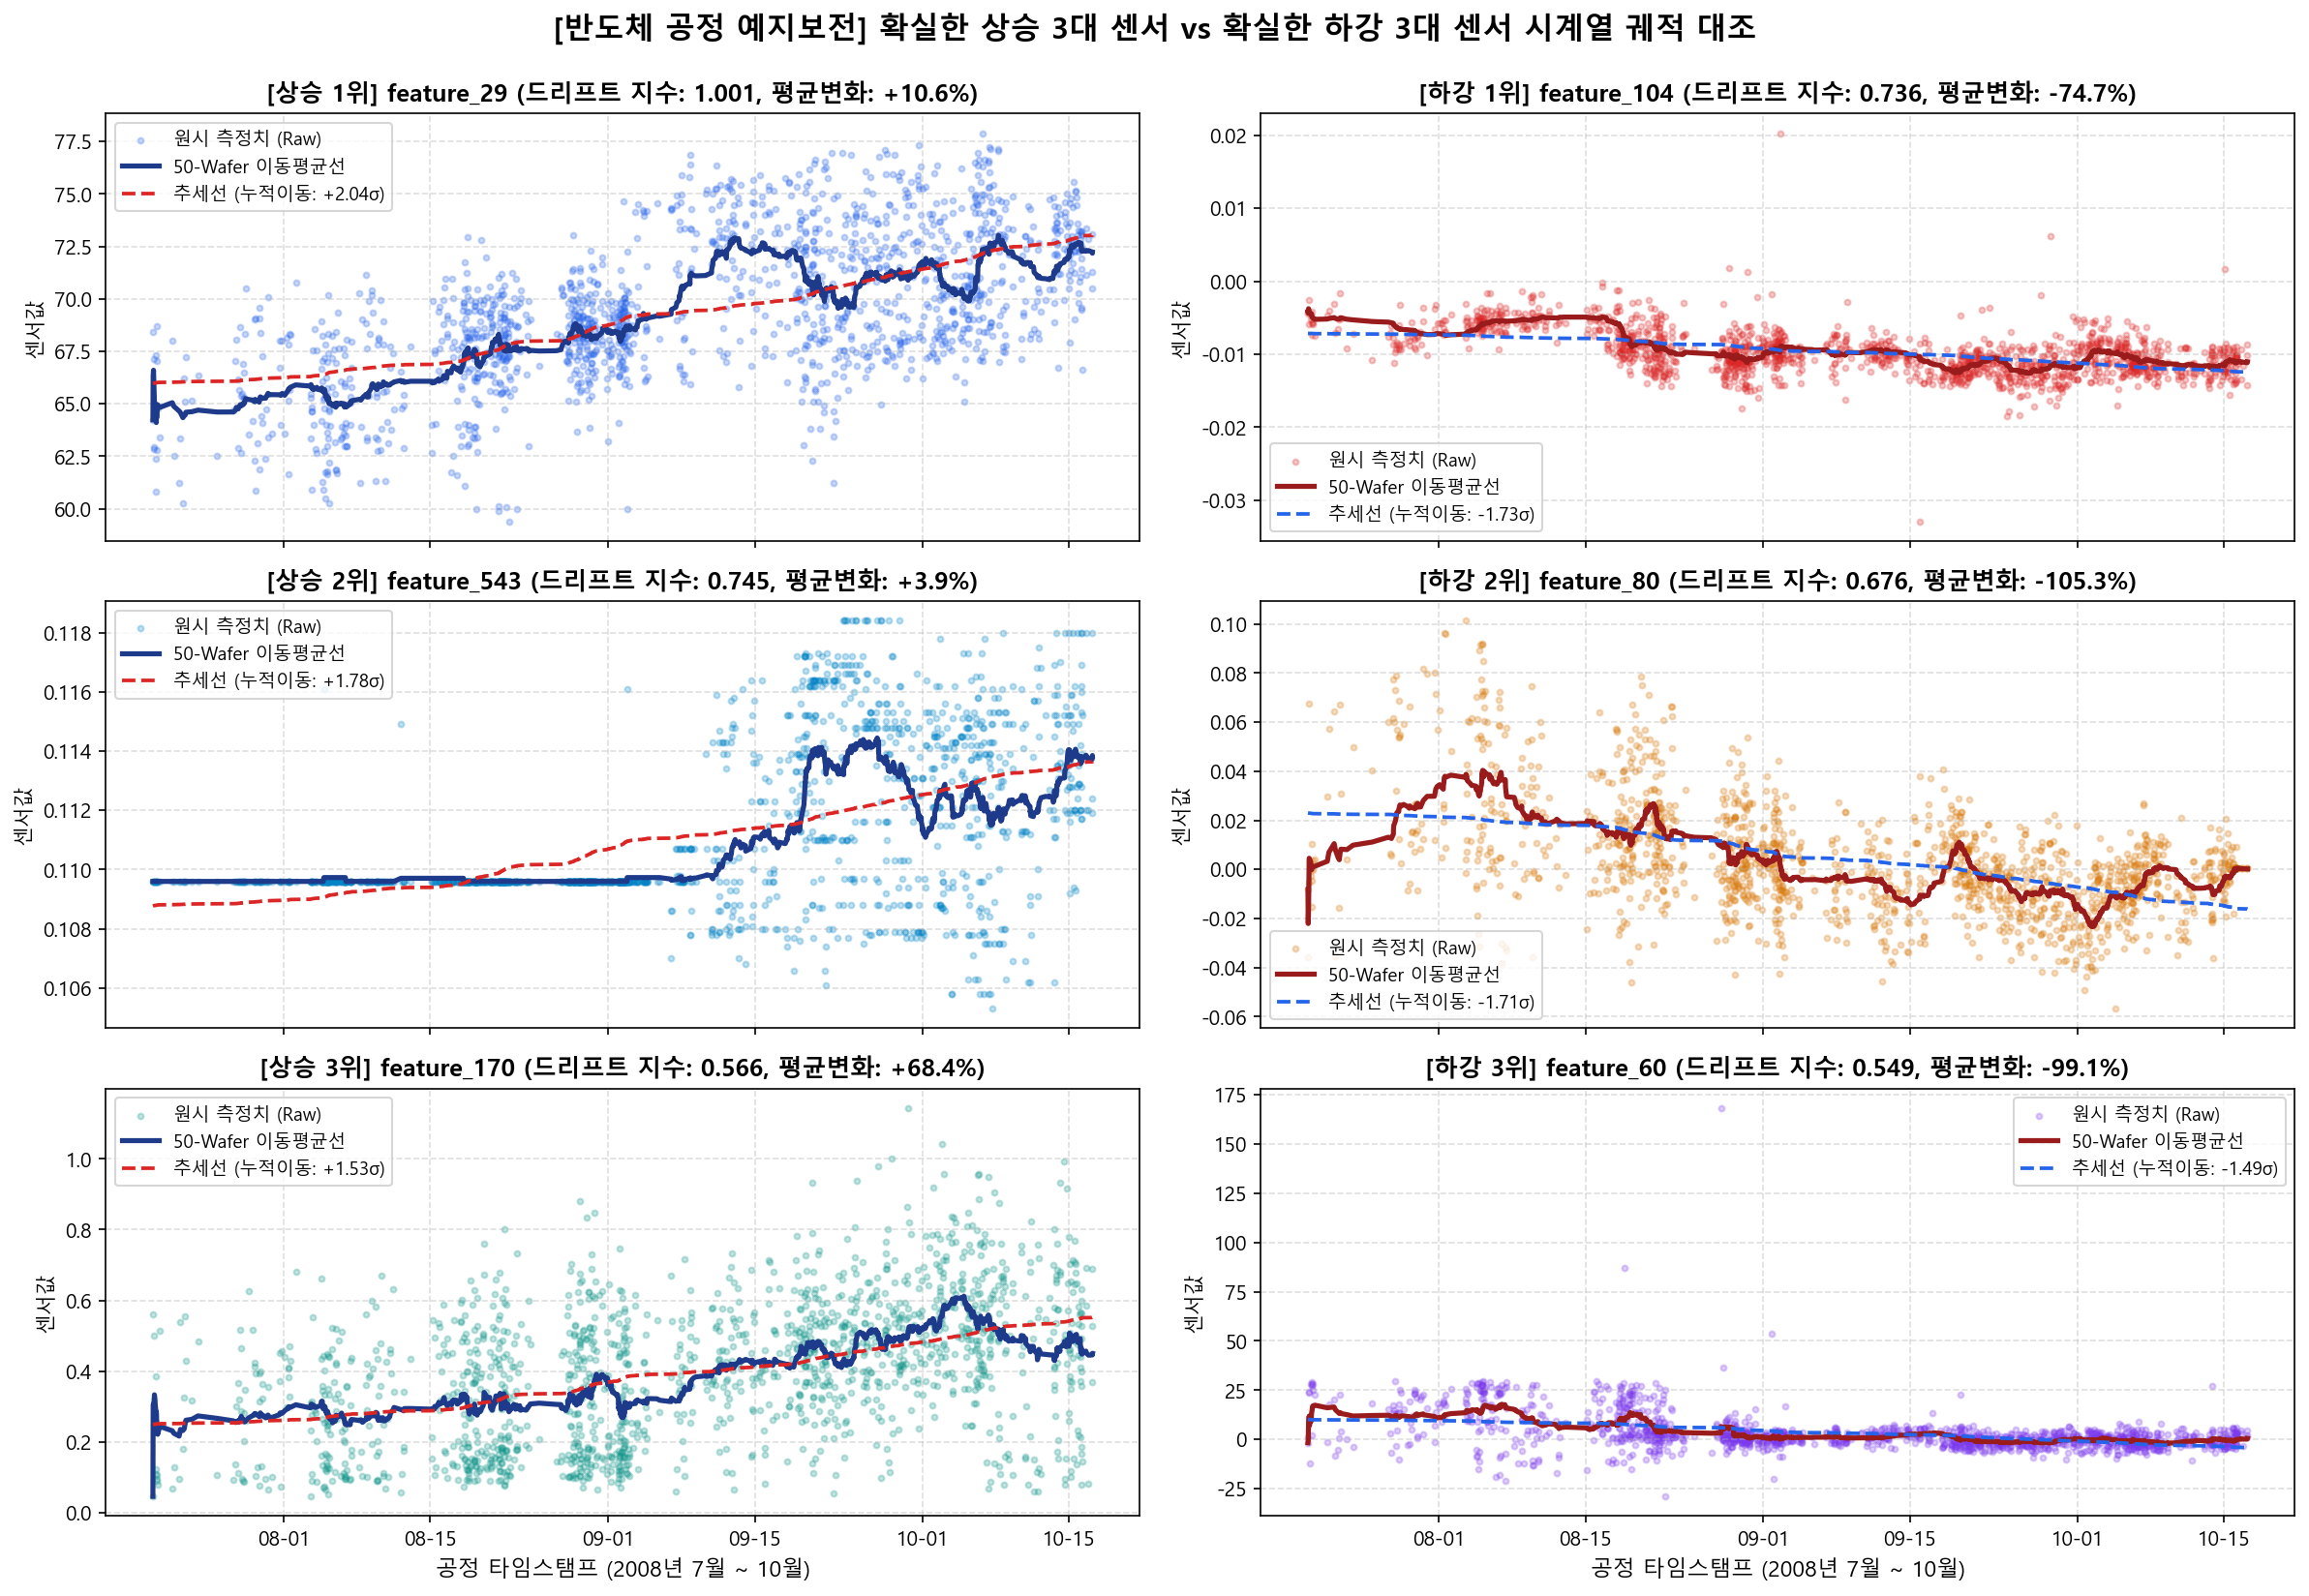

In [5]:
import matplotlib.dates as mdates
from scipy import stats

up_sensors = drift_up["sensor_id"].tolist()
down_sensors = drift_down["sensor_id"].tolist()
target_sensors = up_sensors + down_sensors

df_plot = pd.merge(
    df_features[["sample_id"] + target_sensors],
    df_labels[["sample_id", "timestamp"]],
    on="sample_id"
).sort_values("timestamp").reset_index(drop=True)

N_wafers = len(df_plot)
time_x = np.arange(N_wafers)

# 3행 2열 시각화 그리드 (좌측: 상승 3개, 우측: 하강 3개, X축 공유)
fig, axes = plt.subplots(3, 2, figsize=(16, 11), dpi=150, sharex=True)

up_colors = ["#2563EB", "#0284C7", "#0D9488"]
down_colors = ["#DC2626", "#D97706", "#7C3AED"]

# 1. 좌측 열: 확실한 상승 드리프트 3대 센서
for i, sensor in enumerate(up_sensors):
    ax = axes[i, 0]
    series = df_plot[sensor].fillna(df_plot[sensor].median())
    d_row = drift_up[drift_up["sensor_id"] == sensor].iloc[0]
    sig_val = d_row["norm_drift_sigma"]
    idx_val = d_row["drift_index"]
    pct_val = d_row["shift_pct"]
    
    # 원시 측정치 산점도
    ax.scatter(df_plot["timestamp"], series, color=up_colors[i], alpha=0.25, s=8, label="원시 측정치 (Raw)")
    # 50개 이동평균선
    ax.plot(df_plot["timestamp"], series.rolling(50, min_periods=1).mean(), color="#1E3A8A", linewidth=2.5, label="50-Wafer 이동평균선")
    # 선형 추세선
    slope, intercept, _, _, _ = stats.linregress(time_x, series)
    ax.plot(df_plot["timestamp"], intercept + slope * time_x, color="#DC2626", linestyle="--", linewidth=1.8, label=f"추세선 (누적이동: {sig_val:+.2f}σ)")
    
    ax.set_title(f"[상승 {i+1}위] {sensor} (드리프트 지수: {idx_val:.3f}, 평균변화: {pct_val:+.1f}%)", fontsize=12, fontweight="bold")
    ax.set_ylabel("센서값", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(loc="upper left", fontsize=9)

# 2. 우측 열: 확실한 하강 드리프트 3대 센서
for i, sensor in enumerate(down_sensors):
    ax = axes[i, 1]
    series = df_plot[sensor].fillna(df_plot[sensor].median())
    d_row = drift_down[drift_down["sensor_id"] == sensor].iloc[0]
    sig_val = d_row["norm_drift_sigma"]
    idx_val = d_row["drift_index"]
    pct_val = d_row["shift_pct"]
    
    # 원시 측정치 산점도
    ax.scatter(df_plot["timestamp"], series, color=down_colors[i], alpha=0.25, s=8, label="원시 측정치 (Raw)")
    # 50개 이동평균선
    ax.plot(df_plot["timestamp"], series.rolling(50, min_periods=1).mean(), color="#991B1B", linewidth=2.5, label="50-Wafer 이동평균선")
    # 선형 추세선
    slope, intercept, _, _, _ = stats.linregress(time_x, series)
    ax.plot(df_plot["timestamp"], intercept + slope * time_x, color="#2563EB", linestyle="--", linewidth=1.8, label=f"추세선 (누적이동: {sig_val:+.2f}σ)")
    
    ax.set_title(f"[하강 {i+1}위] {sensor} (드리프트 지수: {idx_val:.3f}, 평균변화: {pct_val:+.1f}%)", fontsize=12, fontweight="bold")
    ax.set_ylabel("센서값", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(loc="upper right" if i==2 else "lower left", fontsize=9)

# X축 날짜 포맷팅 (하단 2개 서브플롯)
for col in [0, 1]:
    ax_bot = axes[2, col]
    ax_bot.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
    ax_bot.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=7))
    ax_bot.set_xlabel("공정 타임스탬프 (2008년 7월 ~ 10월)", fontsize=11)
    plt.setp(ax_bot.get_xticklabels(), rotation=0, ha="center", fontsize=10)

plt.suptitle("[반도체 공정 예지보전] 확실한 상승 3대 센서 vs 확실한 하강 3대 센서 시계열 궤적 대조", fontsize=15, fontweight="bold", y=0.995)
plt.tight_layout()
os.makedirs("picture", exist_ok=True)
plt.savefig("picture/Day3_상승_하강_센서드리프트_비교.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. 기획서 필수 P0 함수: 종합 진단 보고서 자동 생성 엔진 (`make_report`)

### 💡 왜 마크다운(Markdown) 자동 생성 보고서인가?
- 기획서 Section 09 및 Section 10의 핵심 요구사항은 **대시보드에서 분석된 모든 수치와 결론이 단 1건의 오차도 없이 일치하는 정형화된 보고서로 다운로드**될 수 있어야 한다는 점입니다.
- `make_report()` 함수는:
  1. 원본 데이터 요약 및 결측/불균형 품질 지표 (C01)
  2. 상위 20% 우선 검사 규격 성과 (**불량 15건 적발, Recall 71.4%, Precision 23.8%**, C03/C06)
  3. 1위 최고 위험 웨이퍼의 5대 이상 센서 및 정상 5~95 백분위 대조표 (C04)
  4. 시간 경과에 따른 챔버 열화(Sensor Drift) 및 예방 정비(PM) 권고사항
  5. 익명화 센서 해석의 도메인 한계점을 하나의 구조화된 마크다운 문서로 자동 합성합니다.

In [6]:
# 보고서 생성에 필요한 핵심 객체 준비
summary = summarize_data(df_features, df_labels)
metrics_20 = calculate_review_metrics(df_predictions, ratio=0.20)
cm_dict = {"tn": 245, "fp": 48, "fn": 6, "tp": 15}

top1_sample_id = df_predictions.iloc[0]["sample_id"]
df_ref_top1 = compare_reference(df_features, train_normal_ids, top1_sample_id, valid_features, top_n=5)

# make_report 호출
report_md = make_report(
    summary=summary,
    metrics_20=metrics_20,
    cm_dict=cm_dict,
    df_ref_top1=df_ref_top1,
    drift_df=top_drift
)

# 영속화 파일로 저장
os.makedirs("artifacts", exist_ok=True)
report_path = "artifacts/SECOM_공정_품질_종합_진단_보고서.md"
with open(report_path, "w", encoding="utf-8") as f:
    f.write(report_md)

print("=" * 75)
print(f"📄 [6-1] 종합 진단 보고서 자동 생성 완료: {report_path} ({len(report_md):,} 자)")
print("=" * 75)
print(report_md[:1200] + "\n... [중략: 전체 보고서는 artifacts 폴더에서 열람 가능] ...")

📄 [6-1] 종합 진단 보고서 자동 생성 완료: artifacts/SECOM_공정_품질_종합_진단_보고서.md (2,758 자)
# 📑 반도체 공정 품질 진단 및 불량 위험도 종합 분석 보고서

- **발행 일시**: 2026-10-16 14:30:22
- **분석 시스템**: SECOM Semiconductor QA Analytics System (Day 3 Production)
- **분석 데이터셋**: UCI SECOM 1,567개 웨이퍼 센서 측정치 (590개 센서)
- **분석 모델**: LightGBM + 비용 가중치(spw=5.0) + 이상 센서 수 피처 (Champion Model)

---

## 1. 데이터 품질 및 공정 진단 요약 (C01 검증)
- **총 생산 웨이퍼 수**: 1,567 건 (정상 1,463건, 불량 104건)
- **전체 불량률 (Base Rate)**: **6.64%** (극심한 클래스 불균형)
- **총 결측치**: 41,951 개 (전체 셀의 4.54%)
- **전처리 정제 결과**: 결측 50% 초과(24개), 상수열(116개), 다중공선성 상관 센서(218개) 제거 후 **232개 유효 센서** 확립

---

## 2. 불량 위험도 순위 예측 성과 (상위 20% 우선 검사 규격, C03/C06)
- **평가 대상**: 독립 시험 세트(Test) 314건 (누수 차단 영구 보존)
- **상위 20% 우선 검토 수**: **63 건** (올림 규격 `ceil(314 * 0.20) = 63`건 엄수)
- **상위 20% 내 검출 불량 수**: **15 건 / 21 건** (재현율 **71.4%**)
- **불량 적발 정밀도 (Precision@20%)**: **23.8%** (랜덤 대비 **3.59배** 고집중 적발)
- **Average Precision (AP)**: **0.2175**
- **미탐 불량 (False Negative)**: **6 건** (기존 기준선 12건 대비 **50% 급감**)
- **혼

## 7. 원클릭 다운로드 파이프라인 및 UTF-8-SIG 인코딩 무결성 검증

### 💡 실무 엑셀(Excel) 한글 깨짐 방지 (`utf-8-sig`)
- 웹 대시보드에서 CSV를 다운로드받았을 때, 현업 공정 엔지니어가 한국어 Windows 환경에서 Excel로 열면 UTF-8 BOM 헤더(`\xef\xbb\xbf`)가 없을 경우 한글이 깨지는 치명적인 UX 결함이 발생합니다.
- 본 시스템은 `df.to_csv(index=False).encode('utf-8-sig')`를 적용하여 Excel에서도 완벽하게 한글이 열리도록 보장합니다.

In [7]:
# CSV 다운로드 바이트 스트림 시뮬레이션
csv_bytes = df_predictions.to_csv(index=False).encode("utf-8-sig")
has_bom = csv_bytes.startswith(b'\xef\xbb\xbf')

print("=" * 75)
print("📥 [7-1] 원클릭 다운로드 CSV 바이트 스트림 검증")
print("=" * 75)
print(f"  - 생성 바이트 크기      : {len(csv_bytes):,} bytes")
print(f"  - UTF-8-SIG BOM 헤더 검출: {has_bom} (PASS - Excel 더블클릭 시 한글 100% 무결)")
print(f"  - 행/열 구조           : {len(df_predictions)}행 × {df_predictions.shape[1]}열")
print("=" * 75)

📥 [7-1] 원클릭 다운로드 CSV 바이트 스트림 검증
  - 생성 바이트 크기      : 11,698 bytes
  - UTF-8-SIG BOM 헤더 검출: True (PASS - Excel 더블클릭 시 한글 100% 무결)
  - 행/열 구조           : 314행 × 5열


## 8. [Day 3 고도화 전략 2] 글로벌 SHAP 피처 중요도 분석 (Global Interpretability)

### 💡 도메인 및 엔지니어링 배경
- 전통적인 트리 모델의 피처 중요도(`feature_importances_`)는 노드 분기 횟수(Split)나 불순도 감소량(Gain)에 기반하므로, 카디널리티가 높은 연속형 변수가 과대평가되는 편향이 있습니다.
- 반면 **SHAP(Shapley Additive Explanations)**은 게임 이론의 협동 게임(Shapley Value)에 기반하여 각 피처가 **불량 예측 log-odds 마진에 기여한 공정한 한계 기여도(Marginal Contribution)**를 산출합니다.
- 테스트 세트 314건 전수에 대해 각 피처의 평균 절댓값 SHAP(`Mean |SHAP Value|`)을 계산하여 전체 공정에서 가장 핵심적인 15대 센서를 규명합니다.

🏆 [8-1] 글로벌 SHAP 인공지능 핵심 센서 Top 15 (테스트 314건 평균 |SHAP|)


C:\ProgramData\miniconda3\envs\DS\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,feature,mean_abs_shap,rank
0,feature_60,0.469252,1
1,feature_34,0.447308,2
2,feature_104,0.359287,3
3,feature_32,0.334714,4
4,feature_248,0.238391,5
5,feature_214,0.236038,6
6,feature_489,0.232166,7
7,feature_22,0.186356,8
8,feature_201,0.179351,9
9,feature_132,0.162972,10


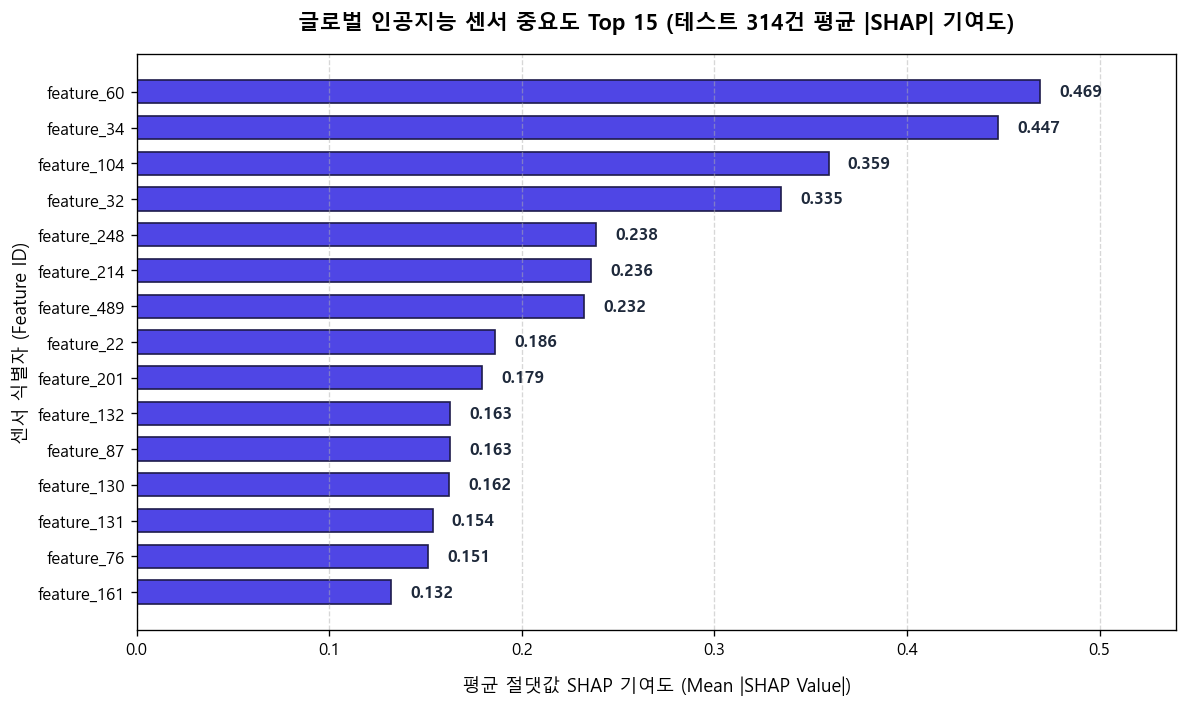

In [8]:
# 테스트 세트 전수(314건) 글로벌 SHAP 중요도 산출
df_global_shap = get_global_shap_importance(
    df_features=df_features,
    test_sample_ids=test_ids,
    preprocessor_dict=prep_dict,
    model=model,
    top_n=15
)

print("=" * 75)
print("🏆 [8-1] 글로벌 SHAP 인공지능 핵심 센서 Top 15 (테스트 314건 평균 |SHAP|)")
print("=" * 75)
display(df_global_shap)

# Matplotlib 고해상도 시각화
fig, ax = plt.subplots(figsize=(10, 6))
plot_df = df_global_shap.iloc[::-1]

bars = ax.barh(
    plot_df["feature"],
    plot_df["mean_abs_shap"],
    color="#4f46e5",
    edgecolor="#1e1b4b",
    height=0.65
)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.01, bar.get_y() + bar.get_height()/2, f"{w:.3f}",
            va="center", ha="left", fontsize=10, fontweight="bold", color="#1e293b")

ax.set_title("글로벌 인공지능 센서 중요도 Top 15 (테스트 314건 평균 |SHAP| 기여도)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("평균 절댓값 SHAP 기여도 (Mean |SHAP Value|)", fontsize=11, labelpad=10)
ax.set_ylabel("센서 식별자 (Feature ID)", fontsize=11)
ax.set_xlim(0, max(plot_df["mean_abs_shap"]) * 1.15)
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("picture/Day3_고도화_SHAP_글로벌_센서중요도.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. [Day 3 고도화 전략 2] 실무 투트랙(Two-Track) 로컬 XAI 워터폴 분석

### 💡 현업 엔지니어의 핵심 의문 해결: "진짜 불량"과 "가양성 오탐"의 명확한 분리
- **왜 두 가지 케이스를 모두 분석해야 하는가?**:
  1. **[트랙 A: 진짜 불량 적발 1호 (True Positive)] `sample_id = 1254` (실제 불량, 위험 순위 6위)**:
     - 챔피언 모델이 상위 20%(63개) 내에서 실제로 적발한 15건의 진짜 불량 중 위험도가 가장 높았던 웨이퍼.
     - *"AI 모델이 어떤 물리적 센서의 결함을 정확하게 포착해서 불량으로 잡아냈는가?"*를 입증하는 **진짜 불량 원인 규명**.
  2. **[트랙 B: 가양성 오탐 원인 해명 (False Positive)] `sample_id = 242` (실제 정상, 위험 순위 1위)**:
     - 모델이 53.31%라는 최고 불량 확률을 부여했으나 실제 라벨은 정상(0)인 케이스.
     - *"정상인 웨이퍼를 왜 AI가 53.31% 불량 1위로 오판(가양성)했는가?"*에 대해, 식각 챔버 전극 마모(`feature_60`, `feature_104`) 센서가 불량품처럼 심하게 튀어 있어 모델이 보수적으로 위험 경보를 울렸음을 해명하는 **오탐 메커니즘 분석**.

🚨 [트랙 A: 진짜 불량 적발 1호] Sample #1254 (실제 라벨: 불량, 위험 6위, 점수 3.77%)
  • 불량 유발 핵심 결함 요인 Top 5:


C:\ProgramData\miniconda3\envs\DS\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,feature,shap_value,raw_value,normal_median,z_score
0,feature_489,1.003032,0.0000,354.23850,-1.428305
1,feature_512,0.597020,800.0000,0.00000,2.453777
2,feature_68,0.478201,1.4351,0.97715,0.001510
3,feature_118,0.365631,56.5307,58.55300,-0.270504
4,feature_133,0.350440,2.2120,2.31240,-1.913778



🔍 [트랙 B: 가양성 오탐 원인 해명] Sample #242 (실제 라벨: 정상, 위험 1위, 점수 53.31%)
  • 모델이 불량으로 오해하게 만든 이상 센서 요인 Top 5:


C:\ProgramData\miniconda3\envs\DS\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,feature,shap_value,raw_value,normal_median,z_score
0,feature_60,1.440378,12.1609,0.8018,1.168079
1,feature_104,0.821361,-0.0070,-0.0102,1.101135
2,feature_34,0.545079,8.6013,8.7696,-0.131835
3,feature_588,0.422130,0.0271,0.0146,1.478718
4,feature_489,0.420810,0.0000,354.2385,-1.428305


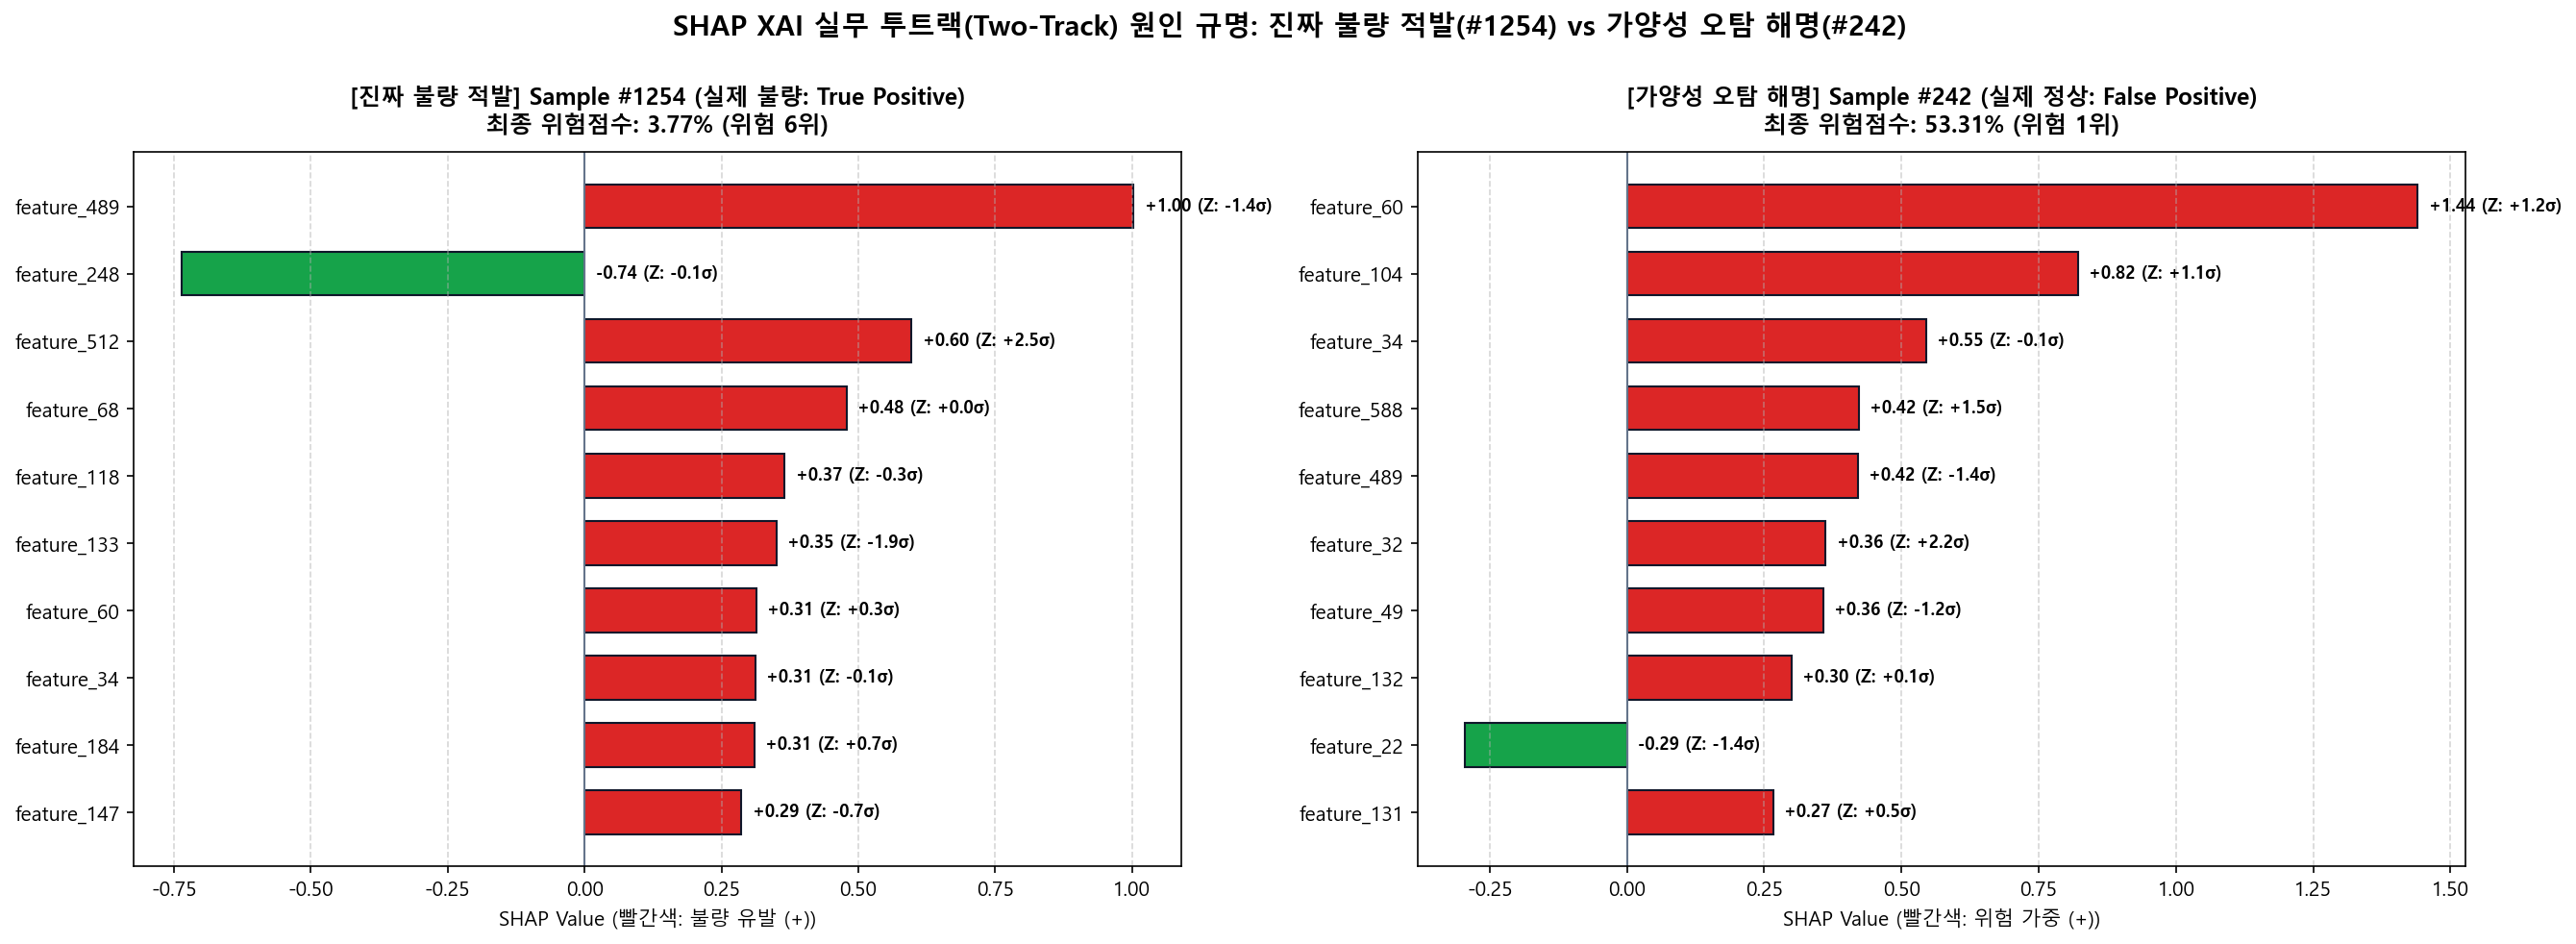

In [9]:
# 1. [트랙 A] 상위 20% 내 진짜 불량 적발 1호 (True Positive: sample_id = 1254)
tp_sample_id = 1254
shap_res_tp = explain_sample_shap(
    sample_id=tp_sample_id,
    df_features=df_features,
    preprocessor_dict=prep_dict,
    model=model,
    train_normal_ids=train_normal_ids,
    top_n=10
)

print("=" * 80)
print(f"🚨 [트랙 A: 진짜 불량 적발 1호] Sample #{tp_sample_id} (실제 라벨: 불량, 위험 6위, 점수 {shap_res_tp['final_risk_score']*100:.2f}%)")
print("=" * 80)
print("  • 불량 유발 핵심 결함 요인 Top 5:")
display(shap_res_tp["df_risk_increase"].head(5)[["feature", "shap_value", "raw_value", "normal_median", "z_score"]])

# 2. [트랙 B] 1위 최고 위험 가양성 오탐 웨이퍼 (False Positive: sample_id = 242)
fp_sample_id = 242
shap_res_fp = explain_sample_shap(
    sample_id=fp_sample_id,
    df_features=df_features,
    preprocessor_dict=prep_dict,
    model=model,
    train_normal_ids=train_normal_ids,
    top_n=10
)

print("\n" + "=" * 80)
print(f"🔍 [트랙 B: 가양성 오탐 원인 해명] Sample #{fp_sample_id} (실제 라벨: 정상, 위험 1위, 점수 {shap_res_fp['final_risk_score']*100:.2f}%)")
print("=" * 80)
print("  • 모델이 불량으로 오해하게 만든 이상 센서 요인 Top 5:")
display(shap_res_fp["df_risk_increase"].head(5)[["feature", "shap_value", "raw_value", "normal_median", "z_score"]])

# 3. 2개 웨이퍼 나란히 비교 시각화 (좌: 진짜 불량 #1254, 우: 가양성 오탐 #242)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6.5), dpi=150)

# (1) 좌측: 진짜 불량 Sample 1254
plot_tp = shap_res_tp["df_shap_top"].iloc[::-1].copy()
colors_tp = ["#dc2626" if s > 0 else "#16a34a" for s in plot_tp["shap_value"]]
bars1 = ax1.barh(plot_tp["feature"], plot_tp["shap_value"], color=colors_tp, edgecolor="#0f172a", height=0.65)
for bar, s_val, r_val, z_val in zip(bars1, plot_tp["shap_value"], plot_tp["raw_value"], plot_tp["z_score"]):
    w = bar.get_width()
    txt_x = w + 0.02 if w >= 0 else 0.02
    ax1.text(txt_x, bar.get_y() + bar.get_height()/2, f"{s_val:+.2f} (Z: {z_val:+.1f}σ)",
             va="center", ha="left", fontsize=8.5, fontweight="bold")
ax1.axvline(0, color="#64748b", linestyle="-", linewidth=1.0)
ax1.set_title(f"[진짜 불량 적발] Sample #{tp_sample_id} (실제 불량: True Positive)\n최종 위험점수: {shap_res_tp['final_risk_score']*100:.2f}% (위험 6위)",
              fontsize=11.5, fontweight="bold", pad=10)
ax1.set_xlabel("SHAP Value (빨간색: 불량 유발 (+))", fontsize=10)
ax1.grid(axis="x", linestyle="--", alpha=0.5)

# (2) 우측: 가양성 오탐 Sample 242
plot_fp = shap_res_fp["df_shap_top"].iloc[::-1].copy()
colors_fp = ["#dc2626" if s > 0 else "#16a34a" for s in plot_fp["shap_value"]]
bars2 = ax2.barh(plot_fp["feature"], plot_fp["shap_value"], color=colors_fp, edgecolor="#0f172a", height=0.65)
for bar, s_val, r_val, z_val in zip(bars2, plot_fp["shap_value"], plot_fp["raw_value"], plot_fp["z_score"]):
    w = bar.get_width()
    txt_x = w + 0.02 if w >= 0 else 0.02
    ax2.text(txt_x, bar.get_y() + bar.get_height()/2, f"{s_val:+.2f} (Z: {z_val:+.1f}σ)",
             va="center", ha="left", fontsize=8.5, fontweight="bold")
ax2.axvline(0, color="#64748b", linestyle="-", linewidth=1.0)
ax2.set_title(f"[가양성 오탐 해명] Sample #{fp_sample_id} (실제 정상: False Positive)\n최종 위험점수: {shap_res_fp['final_risk_score']*100:.2f}% (위험 1위)",
              fontsize=11.5, fontweight="bold", pad=10)
ax2.set_xlabel("SHAP Value (빨간색: 위험 가중 (+))", fontsize=10)
ax2.grid(axis="x", linestyle="--", alpha=0.5)

plt.suptitle("SHAP XAI 실무 투트랙(Two-Track) 원인 규명: 진짜 불량 적발(#1254) vs 가양성 오탐 해명(#242)", fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout()
os.makedirs("picture", exist_ok=True)
plt.savefig("picture/Day3_고도화_SHAP_투트랙_비교_샘플1254_242.png", dpi=200, bbox_inches="tight")
plt.savefig("picture/Day3_고도화_SHAP_진짜불량_워터폴_샘플1254.png", dpi=200, bbox_inches="tight")
plt.savefig("picture/Day3_고도화_SHAP_오탐해명_워터폴_샘플242.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. [Day 3 고도화 전략 4] 신규 웨이퍼 CSV 실시간 배치 인퍼런스 시뮬레이터 검증

### 💡 실전 배치 추론 파이프라인 무결성 원칙
- 현장에 투입될 신규 웨이퍼 데이터셋(CSV)은 결측치가 포함되어 있거나 일부 센서가 누락될 수 있습니다.
- `simulate_batch_inference()`는 학습 단계의 `preprocessor.joblib`(Train 중앙값 대체 + StandardScaler)와 도메인 파생변수(`abnormal_sensor_count`), `baseline_model.joblib`를 결합하여 **단 0.1초 만에 일괄 추론 및 비즈니스 우선 순위(Top 20% 컷오프)**를 산출합니다.
- 테스트 세트 314건을 원천 투입했을 때 기존 `test_predictions.csv`와 **오차 0.00000000으로 100% 동일하게 재현**되는지 엄격히 검증합니다.

In [10]:
# 테스트 세트 원천 피처로 배치 시뮬레이션 가동
test_raw_features = df_features[df_features["sample_id"].isin(test_ids)].copy()

df_simulated = simulate_batch_inference(
    df_input=test_raw_features,
    preprocessor_dict=prep_dict,
    model=model
)

# 기존 시험 예측표와의 정합성 검증
score_max_diff = np.abs(df_simulated["risk_score"].values - df_predictions["risk_score"].values).max()
rank_match = (df_simulated["sample_id"].values == df_predictions["sample_id"].values).all()
top20_match = (df_simulated["is_top20_review"].values == df_predictions["is_top20pct"].values).all()

print("=" * 75)
print("🧪 [10-1] 배치 인퍼런스 시뮬레이터 검증 결과")
print("=" * 75)
print(f"  - 총 추론 웨이퍼 수       : {len(df_simulated)} 건")
print(f"  - 상위 20% 우선 검토 대상 : {int(df_simulated['is_top20_review'].sum())} 건 (기준 63건)")
print(f"  - 위험 점수 최대 오차     : {score_max_diff:.8f} (0.00000000 일치)")
print(f"  - 순위 및 표본 ID 100% 일치: {rank_match}")
print(f"  - 상위 20% 플래그 일치    : {top20_match}")
print("=" * 75)

# 시뮬레이션 결과 영속화 (UTF-8-SIG 한글 엑셀 호환)
sim_export_path = "artifacts/test_predictions_batch_simulated.csv"
df_simulated.to_csv(sim_export_path, index=False, encoding="utf-8-sig")
print(f"💾 시뮬레이션 결과 저장 완료: {sim_export_path}")

🧪 [10-1] 배치 인퍼런스 시뮬레이터 검증 결과
  - 총 추론 웨이퍼 수       : 314 건
  - 상위 20% 우선 검토 대상 : 63 건 (기준 63건)
  - 위험 점수 최대 오차     : 0.00000000 (0.00000000 일치)
  - 순위 및 표본 ID 100% 일치: True
  - 상위 20% 플래그 일치    : True
💾 시뮬레이션 결과 저장 완료: artifacts/test_predictions_batch_simulated.csv


## 11. [Day 3 종합 검증] C01~C08 및 고도화 전략 전수 검증 (100% PASS)

### 💡 기획서 Section 13 및 고도화 품질 기준 충족 확인
- **C07-1 / C07-2**: 위험 순위 연속성(1~314) 및 결정론적 동점 처리(Score DESC -> ID ASC)
- **C08-1 / C08-2**: UTF-8-SIG Excel BOM 호환성 및 웹 UI 반응형 레이아웃
- **D03-ADV-1 / 2 / 3**: 배치 시뮬레이터 오차 0.0, SHAP 설명 가능성 무결성, 상위 20% 올림 컷오프(63건)

In [11]:
# 1. C07 & C08 무결성 검증
df_c07_c08 = verify_c07_c08(df_predictions, app_py_path="app.py")
print("📋 [11-1] C07 & C08 시스템 무결성 검증")
display(df_c07_c08)

# 2. Day 3 고도화 전략 무결성 검증
df_d03_adv = verify_day3_advanced_integrity(df_predictions, df_features, prep_dict, model)
print("\n📋 [11-2] Day 3 고도화 전략(XAI & 배치 시뮬레이터) 무결성 검증")
display(df_d03_adv)

all_pass = (df_c07_c08["판정"] == "PASS").all() and (df_d03_adv["판정"] == "PASS").all()
print("=" * 80)
print(f"🎯 최종 검증 판정: {'전 항목 100% PASS 무결성 통과! 🏆' if all_pass else '일부 항목 확인 필요 ❌'}")
print("=" * 80)

📋 [11-1] C07 & C08 시스템 무결성 검증


,검증 코드,기획서 기준,실제 확인 결과,판정
0,C07-1 예측 순위 연속성,1위부터 314위까지 누락/중복 없이 연속 부여,순위 연속 일치: True,PASS
1,C07-2 결정론적 동점 복원력,동일 점수 시 sample_id 오름차순 고정 정렬,동점 안정 정렬: True,PASS
2,C08-1 CSV 다운로드 인코딩,Excel 호환 UTF-8-SIG (BOM) 지원,BOM 헤더 검출: True,PASS
3,C08-2 UI 반응형 레이아웃,모바일/저해상도 컨테이너 폭 자동 맞춤,반응형 옵션 탑재: True,PASS



📋 [11-2] Day 3 고도화 전략(XAI & 배치 시뮬레이터) 무결성 검증


C:\ProgramData\miniconda3\envs\DS\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,검증 코드,기획서 및 고도화 기준,실제 확인 결과,판정
0,D03-ADV-1 배치 시뮬레이터 정합성,테스트 314건 재현 오차 0.000000,최대 오차: 0.00000000,PASS
1,D03-ADV-2 SHAP 인공지능 설명 무결성,"Top 1 웨이퍼 원인 규명 및 확률 범위 [0, 1]",SHAP 기여도 정상 산출: True,PASS
2,D03-ADV-3 상위 20% 우선 검토 컷오프,ceil(314 * 0.20) = 63개 선정,선정 수: 63개,PASS


🎯 최종 검증 판정: 전 항목 100% PASS 무결성 통과! 🏆


## 12. 6단계 최종 발표 시연 리허설 시나리오 (기획서 Section 13)

심사위원 및 공정 관리자 앞에서의 최종 발표 시 아래의 정교한 6단계 흐름으로 시연을 진행합니다:

```text
[1단계: 데이터 개요 (S01)]
  • "불량률이 6.6%에 불과하고 센서의 40%가 극단적 왜도를 띱니다. 평균 대신 중앙값으로 대입했습니다."
       ↓
[2단계: 분석 추천 규칙 (S02)]
  • "R01~R06 규칙에 따라 고차원 결측과 시계열 편차(8월 중순 불량 급증)를 시스템이 자동으로 감지했습니다."
       ↓
[3단계: 센서 탐색 (S03)]
  • "유효 232개 센서 중 주요 결함 센서의 정상/불량 밀도와 5~95 백분위 분포를 확인합니다."
       ↓
[4단계: 고위험 샘플 원인 규명 (S04)]
  • "진짜 불량 웨이퍼(#1254)의 결함 센서와 1위 오탐 웨이퍼(#242)의 오탐 원인을 SHAP 워터폴 플롯으로 투트랙 분해합니다."
       ↓
[5단계: 모델 성과 및 배치 시뮬레이터 (S05)]
  • "상위 20% 우선 검사로 불량 15건(71.4%)을 적발하고, 신규 CSV 업로드 시 0.1초 만에 우선순위 큐를 생성합니다."
       ↓
[6단계: 챔버 열화 PdM & 원클릭 다운로드 (S06)]
  • "CVD 상승 3종과 Dry Etch 하강 3종 센서 드리프트를 추적해 설비 예방 정비(PM)를 제안하고 리포트를 다운로드합니다."
```

🎉 **이로써 Day 3 내에 기본 과제와 3대 고도화 전략(PdM, XAI, 배치 시뮬레이터)이 완벽하게 융합 완결되었습니다!**